# Particle Filter Localization

The notebook is organised in two blocks:

* **Part 1** contains all the code of the particle filter, collected in two classes (`Robot`, `ParticleFilter`)
  and a few plotting functions. Read it once, together with the slides.
* **Parts 2–7** are short examples that only *use* those classes. Each example is a few lines long and
  follows the steps of the algorithm: move, sense, predict, update, resample.

*Credits: S. Thrun, "Particle Filters in Robotics", UAI 2002.*

<a id="part1"></a>
## 1 · Core code

### 1.1 World and landmarks
The world is a 100 m × 100 m square with 8 landmarks at known positions (the map).
`random.seed` makes every run identical, so when you change a parameter you know that the difference
comes from the parameter and not from chance.

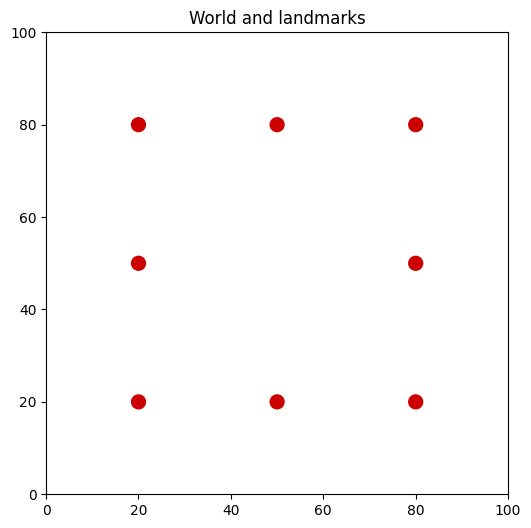

In [81]:
import copy
import random
from math import sin, cos, sqrt, exp, pi, atan2

import matplotlib.pyplot as plt

SEED = 1
random.seed(SEED)

world_size = 100.0
landmarks = [[20.0, 20.0], [20.0, 80.0], [20.0, 50.0],
             [50.0, 20.0], [50.0, 80.0], [80.0, 80.0],
             [80.0, 20.0], [80.0, 50.0]]

fig, ax = plt.subplots(figsize=(6, 6))
for lx, ly in landmarks:
    ax.add_patch(plt.Circle((lx, ly), 1.5, color="#cc0000"))
ax.set_xlim(0, world_size)
ax.set_ylim(0, world_size)
ax.set_aspect("equal")
ax.set_title("World and landmarks")
plt.show()

### 1.2 The `Robot` class
The same class is used for the **real robot** and for every **particle**: a particle is a hypothesis of the
robot pose $(x, y, \theta)$.

| Method | Role in the filter |
|---|---|
| `move(turn, forward)` | motion model (prediction): rotate, then translate, with Gaussian noise |
| `sense()` | the real sensor: noisy distance to every landmark |
| `measurement_prob(Z)` | measurement model (update): how likely is $Z$ if the robot were here? |

**Motion model:**
$\theta' = \theta + \text{turn} + \varepsilon_\theta$, $\;d = \text{forward} + \varepsilon_d$,
$\;x' = x + d\cos\theta'$, $\;y' = y + d\sin\theta'$.

**Measurement model:** the product of one Gaussian per landmark,
$p(Z\mid x)=\prod_j \mathcal N\big(z_j;\ \lVert x-l_j\rVert,\ \sigma^2\big)$.

**Glossary**

| Symbol | Meaning | In the code |
|---|---|---|
| $x, y, \theta$ | position [m] and heading [rad] in the world | `self.x`, `self.y`, `self.orientation` |
| turn, forward | commanded rotation [rad] and distance [m] | arguments of `move` |
| $\varepsilon_\theta,\ \varepsilon_d$ | random noise on the turn and on the distance | `turn_noise`, `forward_noise` (std) |
| $d$ | distance actually travelled | `dist` |
| $Z = (z_1, \dots, z_M)$ | measured distances to the $M$ landmarks | output of `sense()` |
| $l_j$ | position of landmark $j$ | `landmarks[j]` |
| $\lVert x - l_j\rVert$ | distance the robot *would* measure from this pose | `dist` in `measurement_prob` |
| $\sigma$ | standard deviation of the sensor noise | `sense_noise` |
| $\mathcal N(z;\ \mu,\ \sigma^2)$ | Gaussian probability of $z$ with mean $\mu$ and std $\sigma$ | `Gaussian(mu, sigma, x)` |

In [82]:
class Robot:

    def __init__(self):
        # Random pose in the world (this is how particles are initialized)
        self.x = random.random() * world_size
        self.y = random.random() * world_size
        self.orientation = random.random() * 2.0 * pi
        self.forward_noise = 0.0
        self.turn_noise = 0.0
        self.sense_noise = 0.0

    def set(self, new_x, new_y, new_orientation):
        if not 0 <= new_x < world_size:
            raise ValueError("X coordinate out of bound")
        if not 0 <= new_y < world_size:
            raise ValueError("Y coordinate out of bound")
        self.x = float(new_x)
        self.y = float(new_y)
        self.orientation = float(new_orientation) % (2 * pi)

    def set_noise(self, new_f_noise, new_t_noise, new_s_noise):
        self.forward_noise = float(new_f_noise)   # std of the travelled distance [m]
        self.turn_noise = float(new_t_noise)      # std of the turn [rad]
        self.sense_noise = float(new_s_noise)     # std of each range measurement [m]

    def copy(self):
        # An independent copy: resampling must never put the same object twice in the list
        return copy.copy(self)

    def move(self, turn, forward):
        if forward < 0:
            raise ValueError("The robot cannot move backwards")
        orientation = (self.orientation + turn + random.gauss(0.0, self.turn_noise)) % (2 * pi)
        dist = forward + random.gauss(0.0, self.forward_noise)
        res = self.copy()
        res.x = self.x + cos(orientation) * dist
        res.y = self.y + sin(orientation) * dist
        res.orientation = orientation
        return res

    def sense(self, lms=None):
        lms = landmarks if lms is None else lms
        Z = []
        for lx, ly in lms:
            dist = sqrt((self.x - lx) ** 2 + (self.y - ly) ** 2)
            Z.append(dist + random.gauss(0.0, self.sense_noise))
        return Z

    def Gaussian(self, mu, sigma, x):
        # Probability of x for a 1D Gaussian with mean mu and standard deviation sigma
        return exp(-((mu - x) ** 2) / (sigma ** 2) / 2.0) / sqrt(2.0 * pi * (sigma ** 2))

    def measurement_prob(self, measurement, lms=None):
        # Likelihood of the measurement if the robot were at this particle's pose.
        # It only returns a value: it does not modify the particle.
        lms = landmarks if lms is None else lms
        prob = 1.0
        for (lx, ly), z in zip(lms, measurement):
            dist = sqrt((self.x - lx) ** 2 + (self.y - ly) ** 2)
            prob *= self.Gaussian(dist, self.sense_noise, z)
        return prob

    def __repr__(self):
        return "[x=%.2f y=%.2f orient=%.1f deg]" % (self.x, self.y, self.orientation * 180 / pi)

### 1.3 The `ParticleFilter` class
It stores the particles and their weights and implements the steps of the algorithm (slide *Algorithm*):

| Method | Step |
|---|---|
| `init_random()` / `init_guess(...)` | initialization: uniform, or around an initial guess |
| `predict(turn, forward)` | prediction: move every particle with the motion model |
| `update(Z)` | update: weight ← weight × likelihood, then normalize |
| `n_eff()` | effective sample size $N_{\text{eff}} = 1/\sum_i w_i^2$ |
| `resample(method)` | resampling: `"wheel"`, `"multinomial"`, `"stratified"`, `"systematic"` |
| `roughen(...)` | small random jitter after resampling (keeps the particles diverse) |
| `inject_random(fraction)` | replace a fraction of particles with random ones (recovery when lost) |
| `estimate(method)` | one pose from all particles: `"max"` weight or weighted `"mean"` |

In [83]:
class ParticleFilter:

    def __init__(self, N, forward_noise, turn_noise, sense_noise):
        self.N = N
        self.noise = (forward_noise, turn_noise, sense_noise)   # the filter's model of the robot
        self.particles = []
        self.weights = []

    # ---------------------------------------------------------------- initialization
    def init_random(self):
        self.particles = []
        for i in range(self.N):
            p = Robot()                          # random pose
            p.set_noise(*self.noise)
            self.particles.append(p)
        self.weights = [1.0 / self.N] * self.N

    def init_guess(self, x, y, orientation, std_xy, std_theta):
        self.particles = []
        for i in range(self.N):
            p = Robot()
            p.x = random.gauss(x, std_xy)
            p.y = random.gauss(y, std_xy)
            p.orientation = random.gauss(orientation, std_theta) % (2 * pi)
            p.set_noise(*self.noise)
            self.particles.append(p)
        self.weights = [1.0 / self.N] * self.N

    # ---------------------------------------------------------------- prediction
    def predict(self, turn, forward):
        self.particles = [p.move(turn, forward) for p in self.particles]

    # ---------------------------------------------------------------- update
    def update(self, Z, lms=None):
        w = [wi * p.measurement_prob(Z, lms) for wi, p in zip(self.weights, self.particles)]
        total = sum(w)
        if total == 0.0:
            # Every likelihood underflowed to 0.0: no information, keep equal weights
            self.weights = [1.0 / self.N] * self.N
        else:
            self.weights = [wi / total for wi in w]

    def n_eff(self):
        return 1.0 / sum(w * w for w in self.weights)

    # ---------------------------------------------------------------- resampling
    def resample(self, method="wheel"):
        if method == "wheel":
            idx = self._wheel()
        elif method == "multinomial":
            idx = random.choices(range(self.N), weights=self.weights, k=self.N)
        elif method == "stratified":
            idx = self._walk([(k + random.random()) / self.N for k in range(self.N)])
        elif method == "systematic":
            u0 = random.random()
            idx = self._walk([(k + u0) / self.N for k in range(self.N)])
        else:
            raise ValueError("unknown resampling method: " + method)
        self.particles = [self.particles[i].copy() for i in idx]
        self.weights = [1.0 / self.N] * self.N

    def _wheel(self):
        # Resampling wheel, as in the slides
        idx = []
        index = int(random.random() * self.N)
        beta = 0.0
        mw = max(self.weights)
        for i in range(self.N):
            beta += random.random() * 2.0 * mw
            while beta > self.weights[index]:
                beta -= self.weights[index]
                index = (index + 1) % self.N
            idx.append(index)
        return idx

    def _walk(self, pointers):
        # Stratified / systematic: walk once along the cumulative weights
        idx = []
        i, cumulative = 0, self.weights[0]
        for u in pointers:
            while u > cumulative and i < self.N - 1:
                i += 1
                cumulative += self.weights[i]
            idx.append(i)
        return idx

    # ---------------------------------------------------------------- diversity
    def roughen(self, std_xy, std_theta):
        for p in self.particles:
            p.x += random.gauss(0.0, std_xy)
            p.y += random.gauss(0.0, std_xy)
            p.orientation = (p.orientation + random.gauss(0.0, std_theta)) % (2 * pi)

    def inject_random(self, fraction):
        for i in random.sample(range(self.N), int(fraction * self.N)):
            p = Robot()
            p.set_noise(*self.noise)
            self.particles[i] = p

    # ---------------------------------------------------------------- estimate
    def estimate(self, method="mean"):
        if method == "max":
            best = self.particles[self.weights.index(max(self.weights))]
            return best.x, best.y, best.orientation
        x = sum(w * p.x for w, p in zip(self.weights, self.particles))
        y = sum(w * p.y for w, p in zip(self.weights, self.particles))
        # Angles are averaged on the circle: the mean of 359 deg and 1 deg is 0 deg, not 180 deg
        s = sum(w * sin(p.orientation) for w, p in zip(self.weights, self.particles))
        c = sum(w * cos(p.orientation) for w, p in zip(self.weights, self.particles))
        return x, y, atan2(s, c) % (2 * pi)

### 1.4 Plotting and evaluation
Same colors as in the slides: robot (ground truth) in blue, landmarks in red, particles in orange,
resampled particles in green, the estimate in black.

In [84]:
def draw_world(ax, lms=None):
    lms = landmarks if lms is None else lms
    for lx, ly in lms:
        ax.add_patch(plt.Circle((lx, ly), 1.5, facecolor="#cc0000", edgecolor="#330000"))
    ax.set_xlim(0, world_size)
    ax.set_ylim(0, world_size)
    ax.set_aspect("equal")


def draw_robot(ax, r, color="#0000cc", size=3.0, label=None):
    ax.add_patch(plt.Circle((r.x, r.y), 1.2, facecolor=color, edgecolor=color))
    ax.arrow(r.x, r.y, size * cos(r.orientation), size * sin(r.orientation),
             width=0.4, color=color, length_includes_head=True)
    if label is not None:
        ax.text(r.x + 2, r.y + 2, label, fontsize=12, fontweight="bold", color=color)


def plot_path(path, title):
    # A list of robots (one per step), each one labelled with its step number
    fig, ax = plt.subplots(figsize=(6, 6))
    draw_world(ax)
    ax.plot([r.x for r in path], [r.y for r in path], "--", color="#0000cc", alpha=0.5)
    for step, r in enumerate(path):
        draw_robot(ax, r, label=str(step))
    ax.set_title(title)
    plt.show()


def plot_particles(particles, title):
    fig, ax = plt.subplots(figsize=(6, 6))
    draw_world(ax)
    for p in particles:
        ax.plot(p.x, p.y, marker=(3, 0, p.orientation * 180 / pi - 90), markersize=8,
                color="#ff9933", linestyle="None")
    ax.set_title(title)
    plt.show()


def visualization(robot, step, p, pr, weights, estimate=None, lms=None):
    # robot: ground truth · p: particles before resampling · pr: resampled particles
    fig, ax = plt.subplots(figsize=(6, 6))
    draw_world(ax, lms)
    ax.scatter([q.x for q in p], [q.y for q in p], s=12, color="#ff9933", alpha=0.5, label="particles")
    ax.scatter([q.x for q in pr], [q.y for q in pr], s=6, color="#009900", alpha=0.5, label="resampled")
    draw_robot(ax, robot)
    if estimate is not None:
        ax.scatter([estimate[0]], [estimate[1]], s=90, color="black", marker="x", zorder=5, label="estimate")
    ax.set_title("step %d" % step)
    ax.legend(loc="upper right", fontsize=8)
    plt.show()


def position_error(robot, x, y):
    return sqrt((x - robot.x) ** 2 + (y - robot.y) ** 2)

<a id="part2"></a>
## 2 · Moving the robot

The robot starts at (30, 50) facing north. At every step it **turns, then drives forward**.
The numbers on the plot are the step numbers: 0 is the start.

step 0 [x=30.00 y=50.00 orient=90.0 deg]  sense: [31.6, 31.6, 10.0, 36.1, 36.1, 58.3, 58.3, 50.0]
step 1 [x=45.00 y=50.00 orient=0.0 deg]  sense: [39.1, 39.1, 25.0, 30.4, 30.4, 46.1, 46.1, 35.0]
step 2 [x=45.00 y=40.00 orient=270.0 deg]  sense: [32.0, 47.2, 26.9, 20.6, 40.3, 53.2, 40.3, 36.4]


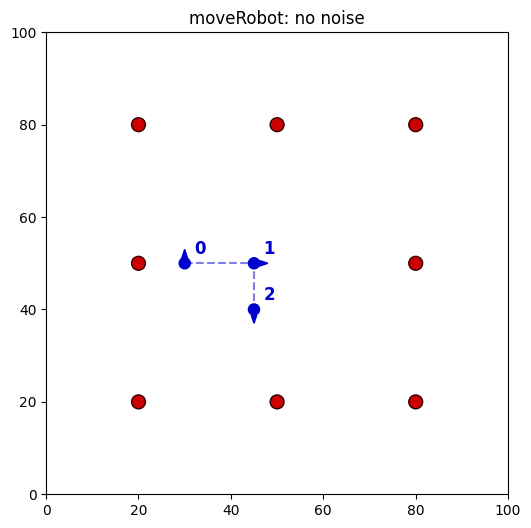

In [85]:
def moveRobot():
    myrobot = Robot()
    myrobot.set(30.0, 50.0, pi / 2)           # start: facing north
    path = [myrobot]

    myrobot = myrobot.move(-pi / 2, 15.0)     # step 1: turn right, drive 15 m
    path.append(myrobot)
    myrobot = myrobot.move(-pi / 2, 10.0)     # step 2: turn right, drive 10 m
    path.append(myrobot)

    for step, r in enumerate(path):
        print("step", step, r, " sense:", [round(z, 1) for z in r.sense()])
    plot_path(path, "moveRobot: no noise")

moveRobot()

Without noise `sense()` returns the exact distances to the 8 landmarks.
Now the same commands with **noise** on the motion and on the sensor: the robot never ends exactly where we
commanded. Run the cell several times.

step 0 [x=30.00 y=50.00 orient=90.0 deg]
step 1 [x=46.01 y=49.92 orient=359.7 deg]
step 2 [x=46.29 y=45.36 orient=273.5 deg]


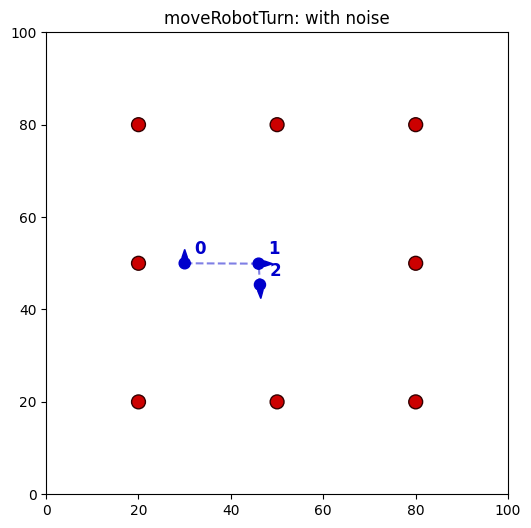

In [86]:
def moveRobotTurn():
    myrobot = Robot()
    myrobot.set_noise(5.0, 0.1, 5.0)          # forward noise [m], turn noise [rad], sense noise [m]
    myrobot.set(30.0, 50.0, pi / 2)
    path = [myrobot]

    myrobot = myrobot.move(-pi / 2, 15.0)
    path.append(myrobot)
    myrobot = myrobot.move(-pi / 2, 10.0)
    path.append(myrobot)

    for step, r in enumerate(path):
        print("step", step, r)
    plot_path(path, "moveRobotTurn: with noise")

moveRobotTurn()

The trajectory used in the rest of the notebook: a circle of radius 25 m (turn 0.1 rad, drive 2.5 m at every
step). The real robot has some motion and sensor noise.

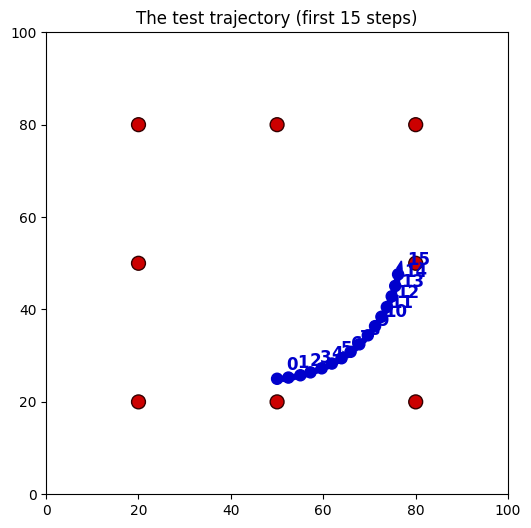

In [87]:
TURN, FORWARD = 0.1, 2.5
TRUE_NOISE = (0.1, 0.02, 2.0)                 # forward, turn, sense noise of the real robot

myrobot = Robot()
myrobot.set(50.0, 25.0, 0.0)
myrobot.set_noise(*TRUE_NOISE)
path = [myrobot]
for step in range(15):
    myrobot = myrobot.move(TURN, FORWARD)
    path.append(myrobot)
plot_path(path, "The test trajectory (first 15 steps)")

<a id="part3"></a>
## 3 · Creating particles

A particle is a `Robot` at a random pose. With no prior knowledge the particles cover the whole map
(**global localization**). If we have a guess (GPS, last known pose) we spread them around it
(**position tracking**).

[[x=2.96 y=4.35 orient=253.2 deg], [x=98.32 y=59.32 orient=141.7 deg], [x=17.03 y=50.22 orient=353.5 deg], [x=77.05 y=53.96 orient=309.7 deg], [x=23.22 y=51.38 orient=342.9 deg]] ...


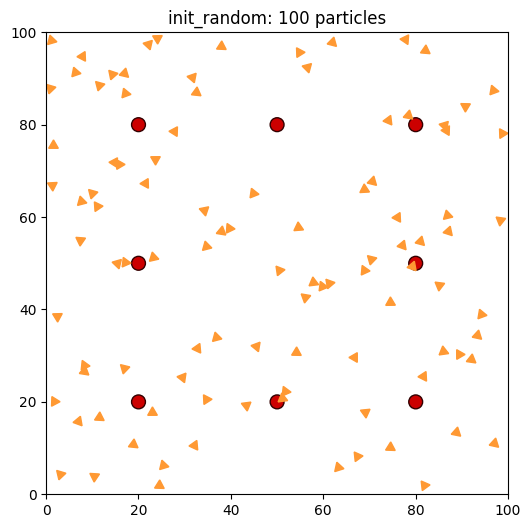

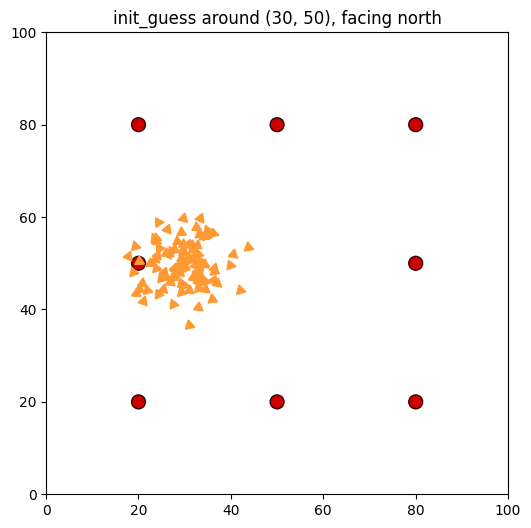

In [88]:
def createParticlesTest():
    pf = ParticleFilter(N=100, forward_noise=0.3, turn_noise=0.05, sense_noise=5.0)

    pf.init_random()
    print(pf.particles[:5], "...")
    plot_particles(pf.particles, "init_random: 100 particles")

    pf.init_guess(30.0, 50.0, pi / 2, std_xy=5.0, std_theta=0.3)
    plot_particles(pf.particles, "init_guess around (30, 50), facing north")

createParticlesTest()

### Prediction: moving the particles with the odometry

The robot does not know where it is, but it knows **how it moved**: the odometry gives the commanded turn and distance.
In the prediction step every particle receives **the same odometry** and moves with the motion model.
Each particle adds its own random noise, because the odometry is never perfect.

Result: the cloud follows the robot, but it **spreads** at every step. Without measurements the uncertainty can only grow.

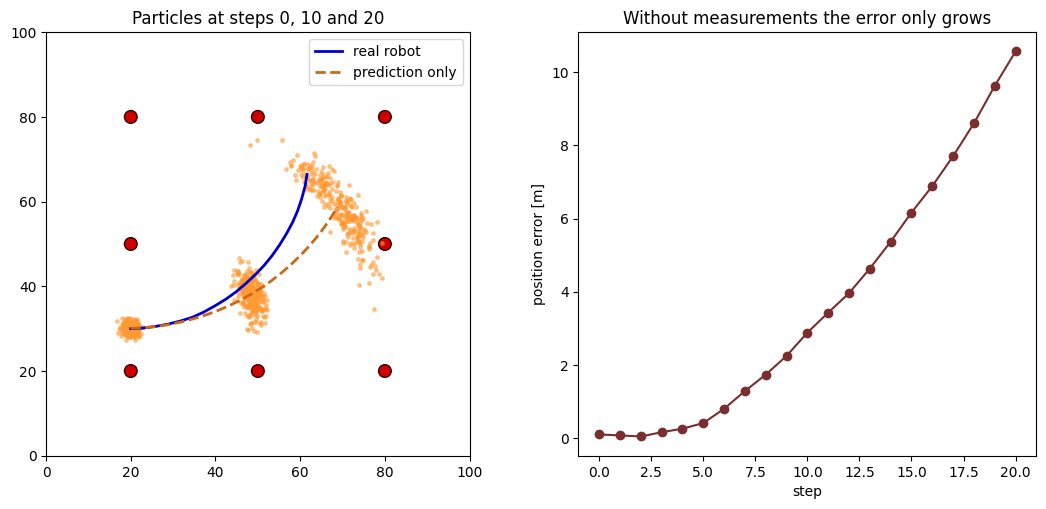

In [89]:
random.seed(SEED)
TURN_ODOM, FORWARD_ODOM = 0.05, 3.0   # what the odometry reports
SLIP = 0.02                           # the real robot turns a bit more (wheel slip)

myrobot = Robot()
myrobot.set(20.0, 30.0, 0.0)
myrobot.set_noise(*TRUE_NOISE)
pf = ParticleFilter(300, forward_noise=0.3, turn_noise=0.05, sense_noise=5.0)
pf.init_guess(20.0, 30.0, 0.0, std_xy=1.0, std_theta=0.05)

truth, pred, error = [], [], []
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
draw_world(axes[0])
for k in range(21):
    if k > 0:
        myrobot = myrobot.move(TURN_ODOM + SLIP, FORWARD_ODOM)   # real motion
        pf.predict(TURN_ODOM, FORWARD_ODOM)                       # prediction: odometry only
    x, y, _ = pf.estimate()
    truth.append((myrobot.x, myrobot.y))
    pred.append((x, y))
    error.append(position_error(myrobot, x, y))
    if k % 10 == 0:
        axes[0].scatter([p.x for p in pf.particles], [p.y for p in pf.particles], s=6, color="#ff9933", alpha=0.5)
axes[0].plot(*zip(*truth), color="#0000cc", lw=2, label="real robot")
axes[0].plot(*zip(*pred), "--", color="#c96a1b", lw=2, label="prediction only")
axes[0].legend()
axes[0].set_title("Particles at steps 0, 10 and 20")
axes[1].plot(error, "o-", color="#7a2e2e")
axes[1].set_xlabel("step")
axes[1].set_ylabel("position error [m]")
axes[1].set_title("Without measurements the error only grows")
plt.show()

### Update: weighting the particles with the measurement

Now the robot **measures** its distances to the landmarks ($Z$).
Each particle asks: *"if the robot were where I am, would it measure $Z$?"*
The answer is `measurement_prob(Z)`, and it becomes the particle's **weight**.

The particles **do not move** in the update: only their weights change.
Particles close to the robot get large weights, the others almost zero.

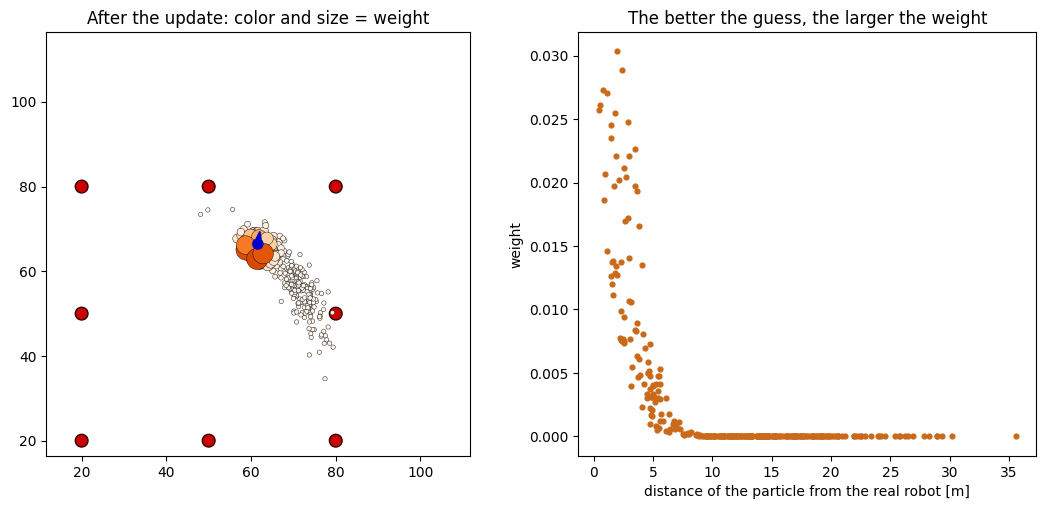

error before the update: 10.6 m   after: 1.3 m


In [90]:
Z = myrobot.sense()
pf.update(Z)

dist = [position_error(myrobot, p.x, p.y) for p in pf.particles]   # how wrong each guess is
w_max = max(pf.weights)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
draw_world(axes[0])
axes[0].scatter([p.x for p in pf.particles], [p.y for p in pf.particles], c=pf.weights, cmap="Oranges",
                s=[10 + 300 * w / w_max for w in pf.weights], edgecolor="k", linewidth=0.3)
draw_robot(axes[0], myrobot)
axes[0].set_xlim(myrobot.x - 50, myrobot.x + 50)
axes[0].set_ylim(myrobot.y - 50, myrobot.y + 50)
axes[0].set_title("After the update: color and size = weight")
axes[1].scatter(dist, pf.weights, s=12, color="#c96a1b")
axes[1].set_xlabel("distance of the particle from the real robot [m]")
axes[1].set_ylabel("weight")
axes[1].set_title("The better the guess, the larger the weight")
plt.show()

x, y, _ = pf.estimate()
print("error before the update: %.1f m   after: %.1f m" % (error[-1], position_error(myrobot, x, y)))

### 4- What happens without resampling?

After each update the weights are multiplied again, step after step. A particle that was a little worse than the others
becomes a bit worse at every step, and its weight quickly goes to ≈ 0.

Two filters run on the same robot: one **never resamples**, the other **resamples at every step**.
$N_{\text{eff}} = 1/\sum_i w_i^2$ counts how many particles really contribute to the estimate.

* **Without resampling** the particles stay spread over the whole area, but only a handful still have a weight.
  We are moving and weighting 500 particles to use about 10 of them (**weight degeneracy**).
* **With resampling** the useless particles are replaced by copies of the good ones, close to the robot,
  and almost all of them count again.

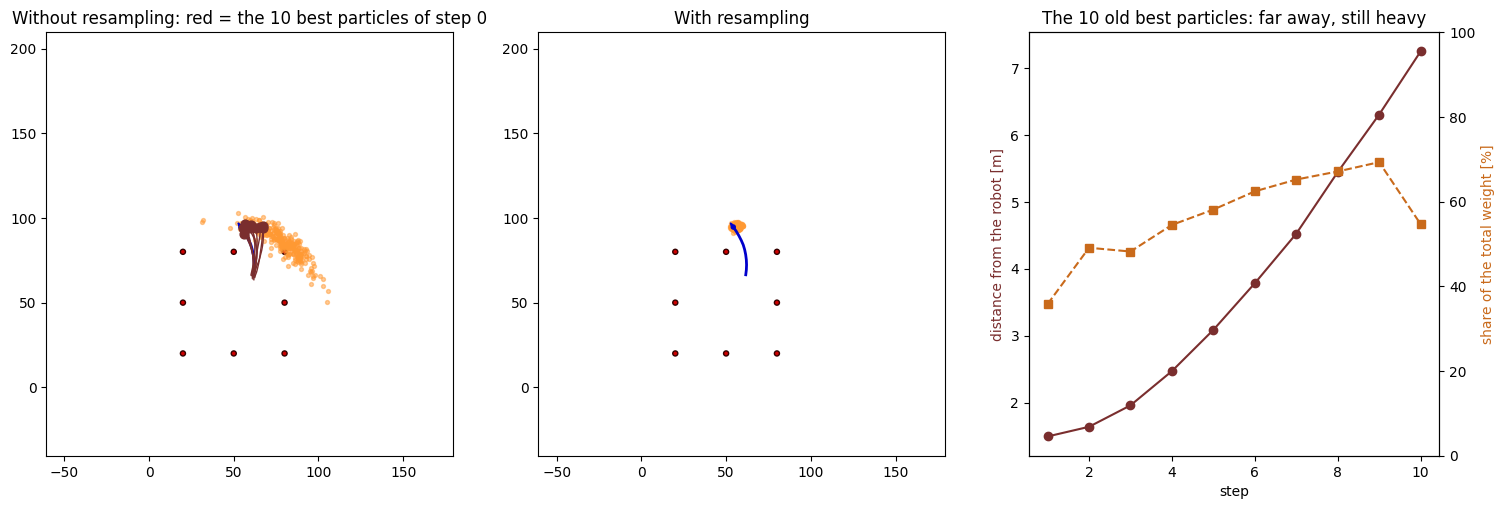

after 10 steps the old best particles are 7.2 m from the robot and still hold 55% of the weight


In [91]:
pf_rs = copy.deepcopy(pf)                                          # a copy that WILL resample
best = sorted(range(pf.N), key=lambda i: -pf.weights[i])[:10]      # the 10 best particles now
paths = {i: [(pf.particles[i].x, pf.particles[i].y)] for i in best}
robot_path = [(myrobot.x, myrobot.y)]
dist_best, weight_best = [], []

for k in range(10):
    myrobot = myrobot.move(TURN_ODOM + SLIP, FORWARD_ODOM)
    Z = myrobot.sense()
    for f in (pf, pf_rs):
        f.predict(TURN_ODOM, FORWARD_ODOM)
        f.update(Z)
    pf_rs.resample("systematic")                                   # only the copy resamples
    pf_rs.roughen(0.3, 0.02)
    robot_path.append((myrobot.x, myrobot.y))
    for i in best:
        paths[i].append((pf.particles[i].x, pf.particles[i].y))
    dist_best.append(sum(position_error(myrobot, pf.particles[i].x, pf.particles[i].y) for i in best) / 10)
    weight_best.append(sum(pf.weights[i] for i in best))

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, f, title in [(axes[0], pf, "Without resampling"), (axes[1], pf_rs, "With resampling")]:
    draw_world(ax)
    ax.scatter([p.x for p in f.particles], [p.y for p in f.particles], s=8, color="#ff9933", alpha=0.5)
    ax.plot(*zip(*robot_path), color="#0000cc", lw=2)
    draw_robot(ax, myrobot)
    ax.set_xlim(myrobot.x - 115, myrobot.x + 125)
    ax.set_ylim(myrobot.y - 135, myrobot.y + 115)
    ax.set_title(title)
for i in best:                                                     # where the old best particles went
    axes[0].plot(*zip(*paths[i]), color="#7a2e2e", lw=1)
    axes[0].scatter(*paths[i][-1], s=40, color="#7a2e2e", zorder=5)
axes[0].set_title("Without resampling: red = the 10 best particles of step 0")
axes[2].plot(range(1, 11), dist_best, "o-", color="#7a2e2e")
axes[2].set_ylabel("distance from the robot [m]", color="#7a2e2e")
ax2 = axes[2].twinx()
ax2.plot(range(1, 11), [100 * w for w in weight_best], "s--", color="#c96a1b")
ax2.set_ylabel("share of the total weight [%]", color="#c96a1b")
ax2.set_ylim(0, 100)
axes[2].set_xlabel("step")
axes[2].set_title("The 10 old best particles: far away, still heavy")
plt.show()

print("after 10 steps the old best particles are %.1f m from the robot and still hold %.0f%% of the weight"
      % (dist_best[-1], 100 * weight_best[-1]))

After a few steps almost all the weight sits on a handful of particles (**weight degeneracy**): the other
particles are still moved and weighted at every step, but they no longer contribute to the estimate.
Resampling solves this.

<a id="part5"></a>
## 5 · Resampling

Resampling draws $N$ new particles; particle $i$ is chosen with probability $w_i$.
We test the four methods of `ParticleFilter.resample` on the example of the slides
(weights 1.4, 0.5, 0.9, 3.2, 1.9, 0.1). Each method is run 2000 times and we count the copies of each particle:
on average particle $i$ should get $N\,w_i$ copies.

In [92]:
def resamplingTest(runs=2000):
    w = [1.4, 0.5, 0.9, 3.2, 1.9, 0.1]
    total = sum(w)
    pf = ParticleFilter(N=len(w), forward_noise=0, turn_noise=0, sense_noise=1)
    print("expected copies:", [round(len(w) * wi / total, 2) for wi in w])

    for method in ["multinomial", "wheel", "stratified", "systematic"]:
        counts = [[0] * runs for _ in w]                   # counts[particle][run]
        for run in range(runs):
            pf.init_random()
            for i, p in enumerate(pf.particles):
                p.id = i                                    # remember who is who
            pf.weights = [wi / total for wi in w]
            pf.resample(method)
            for p in pf.particles:
                counts[p.id][run] += 1
        mean = [sum(c) / runs for c in counts]
        std = [sqrt(sum((x - m) ** 2 for x in c) / runs) for c, m in zip(counts, mean)]
        print("%-12s mean copies %s   spread %s" % (method, [round(m, 2) for m in mean],
                                                     [round(s, 2) for s in std]))

resamplingTest()

expected copies: [1.05, 0.38, 0.68, 2.4, 1.42, 0.08]
multinomial  mean copies [1.05, 0.38, 0.66, 2.4, 1.44, 0.08]   spread [0.94, 0.61, 0.76, 1.17, 1.04, 0.27]
wheel        mean copies [1.04, 0.39, 0.66, 2.45, 1.39, 0.07]   spread [0.85, 0.59, 0.75, 1.06, 0.94, 0.27]
stratified   mean copies [1.05, 0.4, 0.65, 2.4, 1.43, 0.08]   spread [0.21, 0.49, 0.59, 0.59, 0.58, 0.26]
systematic   mean copies [1.06, 0.39, 0.67, 2.41, 1.41, 0.06]   spread [0.23, 0.49, 0.47, 0.49, 0.49, 0.24]


All methods give (approximately) the right number of copies. Stratified and systematic have a much smaller
spread: they add less random noise at every resampling. The wheel is close but not exact: it is a heuristic.

<a id="part6"></a>
## 6 · Full particle filter

One step of the complete filter (slide *Algorithm*):

1. the real robot moves and senses;
2. **predict**: move every particle;
3. **update**: weight the particles with the measurement;
4. **estimate**: one pose from the particles;
5. **resample**, then roughen (small jitter) so that the copies do not stay identical.

All the options are parameters of `fullParticleFilter`, so the experiments of Part 7 are one-line calls.

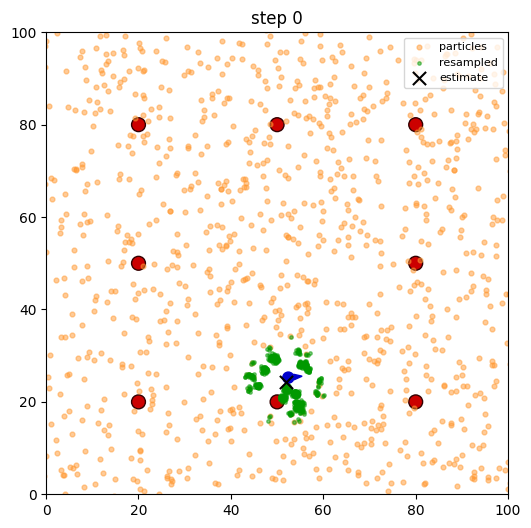

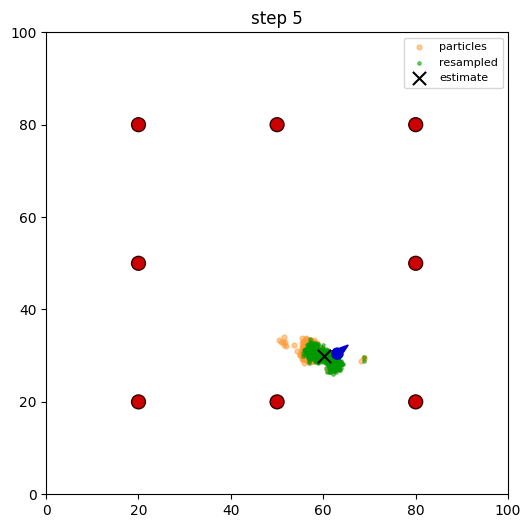

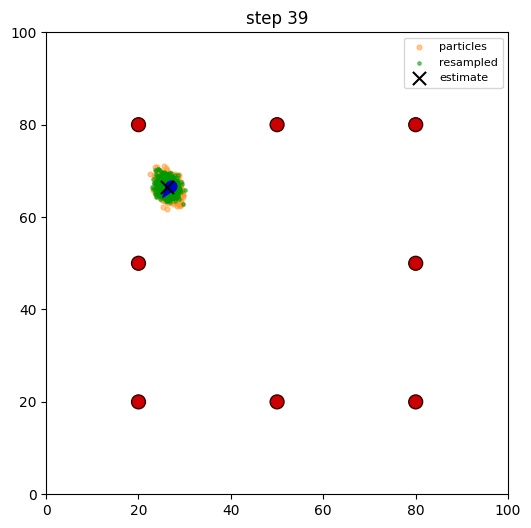

RMSE (second half): 0.50 m


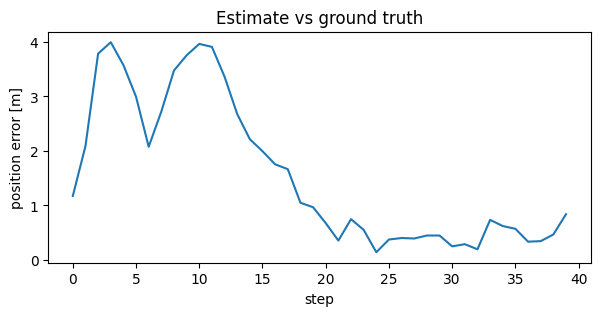

In [93]:
def fullParticleFilter(N=1000, steps=40, resampling="wheel",
                       forward_noise=0.3, turn_noise=0.05, sense_noise=5.0,
                       roughen=(0.3, 0.02), random_fraction=0.0, estimator="mean",
                       lms=None, kidnap_at=None, show_steps=(0, 5, 39), seed=SEED):
    random.seed(seed)
    myrobot = Robot()
    myrobot.set(50.0, 25.0, 0.0)
    myrobot.set_noise(*TRUE_NOISE)

    pf = ParticleFilter(N, forward_noise, turn_noise, sense_noise)
    pf.init_random()
    errors = []

    for t in range(steps):
        # 1. the real robot moves and senses
        myrobot = myrobot.move(TURN, FORWARD)
        if t == kidnap_at:
            myrobot.set(75.0, 75.0, pi)           # someone moves the robot
        Z = myrobot.sense(lms)

        # 2-3. predict and update
        pf.predict(TURN, FORWARD)
        pf.update(Z, lms)

        # 4. estimate
        x, y, theta = pf.estimate(estimator)
        errors.append(position_error(myrobot, x, y))

        # 5. resample
        before, weights = pf.particles, pf.weights
        pf.resample(resampling)
        if roughen:
            pf.roughen(*roughen)
        if random_fraction > 0:
            pf.inject_random(random_fraction)

        if t in show_steps:
            visualization(myrobot, t, before, pf.particles, weights, (x, y), lms)

    return errors


def rmse(errors):
    second_half = errors[len(errors) // 2:]          # after convergence
    return sqrt(sum(e * e for e in second_half) / len(second_half))


errors = fullParticleFilter()
print("RMSE (second half): %.2f m" % rmse(errors))
plt.figure(figsize=(7, 3))
plt.plot(errors)
plt.xlabel("step"); plt.ylabel("position error [m]"); plt.title("Estimate vs ground truth")
plt.show()

<a id="part7"></a>
## 7 · Experiments

Every experiment changes one parameter of `fullParticleFilter`. Each configuration runs with 3 seeds
(same trajectory and noise for every configuration) and we report the RMSE on the second half of the run.

In [94]:
def compare(label, seeds=(1, 2, 3), **params):
    results = [rmse(fullParticleFilter(show_steps=(), seed=s, **params)) for s in seeds]
    print("%-32s RMSE: %s m" % (label, [round(r, 2) for r in results]))

### 7.1 Number of particles
Few particles are fast, but with global localization they may never put a hypothesis near the true pose.

In [73]:
for N in [100, 300, 1000, 2000]:
    compare("N = %d" % N, N=N)

N = 100                          RMSE: [1.4, 0.49, 58.46] m
N = 300                          RMSE: [2.22, 0.94, 50.64] m
N = 1000                         RMSE: [0.5, 0.4, 0.67] m
N = 2000                         RMSE: [0.64, 0.94, 0.68] m


### 7.2 Measurement noise of the filter
The real sensor has $\sigma = 2$ m. What happens if the filter assumes a different value?

In [74]:
for s in [1.0, 2.0, 5.0, 20.0]:
    compare("sense_noise = %.0f" % s, sense_noise=s)

sense_noise = 1                  RMSE: [62.77, 87.78, 1.5] m
sense_noise = 2                  RMSE: [3.92, 83.53, 0.86] m
sense_noise = 5                  RMSE: [0.5, 0.4, 0.67] m
sense_noise = 20                 RMSE: [0.81, 1.06, 1.22] m


A too small $\sigma$ makes the likelihood very peaked: almost every particle gets weight ≈ 0. A too large $\sigma$
makes all particles look alike and the estimate stays wide. A value somewhat **larger** than the real noise
often works best with a finite number of particles.

### 7.3 Resampling method

In [75]:
for method in ["wheel", "multinomial", "stratified", "systematic"]:
    compare(method, resampling=method)

wheel                            RMSE: [0.5, 0.4, 0.67] m
multinomial                      RMSE: [0.68, 0.79, 0.47] m
stratified                       RMSE: [0.77, 0.69, 0.47] m
systematic                       RMSE: [0.46, 0.58, 0.52] m


### 7.4 Roughening
Without jitter, after resampling many particles are identical copies (**sample impoverishment**).

In [76]:
compare("no roughening", roughen=None)
compare("roughening (0.3 m, 0.02 rad)", roughen=(0.3, 0.02))

no roughening                    RMSE: [0.65, 10.8, 1.09] m
roughening (0.3 m, 0.02 rad)     RMSE: [0.5, 0.4, 0.67] m


### 7.5 Fewer landmarks

8 landmarks                      RMSE: [0.5, 0.4, 0.67] m
3 landmarks                      RMSE: [1.31, 1.13, 1.23] m


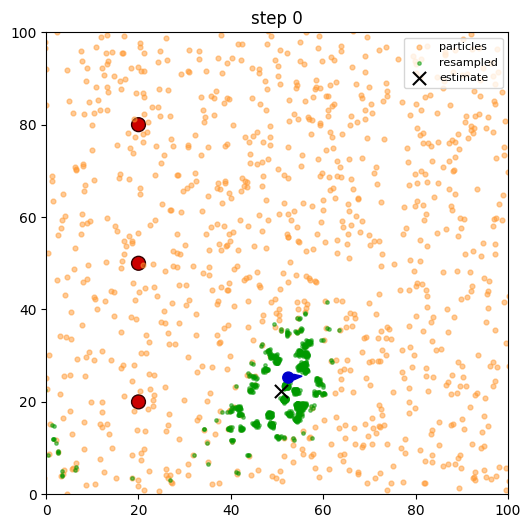

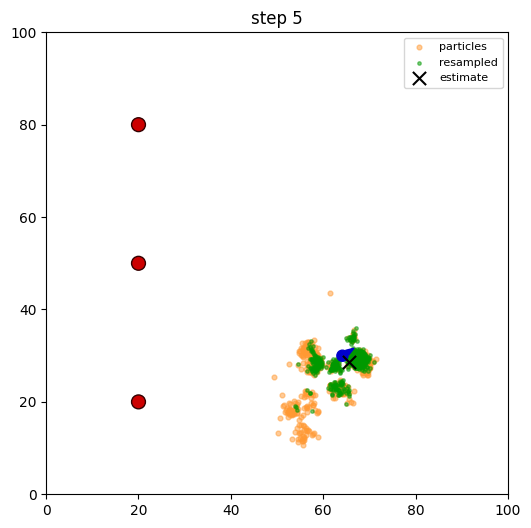

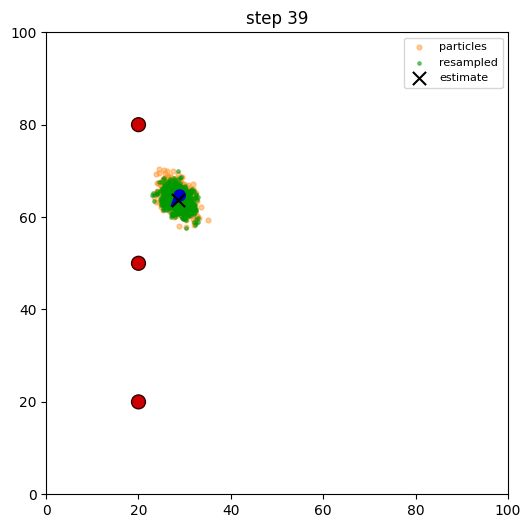

In [77]:
compare("8 landmarks", lms=landmarks)
compare("3 landmarks", lms=landmarks[:3])
errors = fullParticleFilter(lms=landmarks[:3], show_steps=(0, 5, 39))

### 7.6 Max-weight particle vs weighted mean

In [78]:
compare("max weight", estimator="max")
compare("weighted mean", estimator="mean")

max weight                       RMSE: [1.41, 1.3, 1.47] m
weighted mean                    RMSE: [0.5, 0.4, 0.67] m


### 7.7 Kidnapped robot
At step 20 the robot is moved to (75, 75) without the filter knowing. Injecting a small fraction of random
particles at every step lets the filter find the robot again faster.

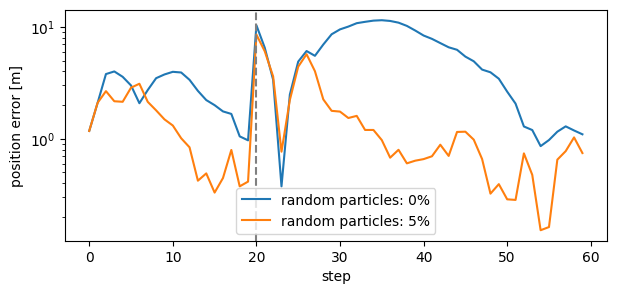

In [79]:
plt.figure(figsize=(7, 3))
for fraction in [0.0, 0.05]:
    errors = fullParticleFilter(steps=60, kidnap_at=20, random_fraction=fraction, show_steps=())
    plt.plot(errors, label="random particles: %d%%" % (100 * fraction))
plt.axvline(20, linestyle="--", color="gray")
plt.yscale("log"); plt.xlabel("step"); plt.ylabel("position error [m]"); plt.legend()
plt.show()

Without random particles the cloud slowly "crawls" towards the robot thanks to the roughening. With 5% random
particles one of them soon lands near the robot and the filter jumps there. The price: while the filter is not lost,
5% of the particles are wasted. Try 1%, 5% and 20%.

<a id="part8"></a>
## 8 · Exercises

**Exercise 1 · Effect of the noise.** Change `forward_noise`, `turn_noise` and `sense_noise` of the filter
(and `TRUE_NOISE` of the robot). When is the filter overconfident? When is it too slow?

**Exercise 2 · Resample only when needed.** Modify `fullParticleFilter` so that it resamples only when
$N_{\text{eff}} < N/2$. Compare RMSE and number of resamplings.

**Exercise 3 · Residual resampling.** Add `"residual"` to `ParticleFilter.resample`: copy particle $i$ exactly
$\lfloor N w_i\rfloor$ times, then fill the remaining slots with systematic resampling on the residual weights.
Check it with `resamplingTest()`.

**Exercise 4 · Log-likelihood.** With many landmarks the product in `measurement_prob` underflows to 0.0.
Write `measurement_log_prob` (a sum of logs) and use it in `update`.

**Exercise 5 · Number of particles.** Find the smallest $N$ that localizes the robot for all three seeds. How does
it change with `init_guess` instead of `init_random`?

In [80]:
# Exercise 3: skeleton
def residual_indices(weights):
    N = len(weights)
    idx = []
    # TODO 1: copy particle i floor(N * w_i) times
    # TODO 2: compute the residual weights and normalize them
    # TODO 3: fill the remaining N - len(idx) slots with systematic resampling
    return idx